# Proyek Analisis Data: Bike Sharing
- **Nama:** Katharina Paskaline Berliana Haryanto
- **Email:** kth.paskaline25@gmail.com
- **ID Dicoding:** kthpaskaline

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

**Konteks bisnis.** Dataset berisi catatan penyewaan sepeda Capital Bikeshare (Washington D.C.) per jam dan per hari selama 2011-2012. Analisis ini membantu tim operasional merencanakan distribusi sepeda, promosi, dan jadwal perawatan.

- **Pertanyaan 1:** Pada jam berapa saja rata-rata penyewaan sepeda melebihi 300 sewa per jam pada hari kerja dibandingkan akhir pekan/libur selama periode 2011-2012, agar tim operasional dapat menjadwalkan distribusi sepeda pada jam-jam tersebut?
- **Pertanyaan 2:** Pada musim dan kondisi cuaca apa rata-rata penyewaan harian turun lebih dari 50% dibandingkan musim dan cuaca terbaiknya selama periode 2011-2012, agar tim pemasaran dan perawatan dapat merencanakan promo serta jadwal maintenance pada periode tersebut?

## Import Semua Packages/Library yang Digunakan

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

Pada tahap ini kedua file dimuat ke dalam DataFrame. day.csv merupakan agregasi harian, sedangkan hour.csv merupakan data per jam. Kolom dteday langsung dibaca sebagai teks dulu supaya masalah tipe data dapat dinilai pada tahap assessing.



#### Load day_df dan hour_df

In [5]:
day_df = pd.read_csv("data/day.csv")
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [6]:
hour_df = pd.read_csv("data/hour.csv")
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- `day_df` berisi data harian (16 kolom) dan `hour_df` berisi data per jam (17 kolom, ada tambahan kolom `hr`).
- Keduanya memuat kolom kalender (`season`, `yr`, `workingday`, dll.), cuaca (`weathersit`, `temp`, `hum`, `windspeed`), dan penyewaan (`casual`, `registered`, `cnt`).
- Banyak kolom masih berupa kode angka dan nilai cuaca masih ternormalisasi (0-1).

### Assessing Data

Penilaian kualitas data dilakukan dengan memeriksa: tipe data, *missing value*, duplikasi, nilai tidak valid, konsistensi antar-file, kelengkapan data per jam, dan *outlier*.

#### Identifying Data Quality Problems (tipe data, nilai tidak valid, jam hilang, outlier)

In [7]:
## Menilai Tabel day_df
day_df.info()
print("Jumlah missing value :", day_df.isna().sum().sum())
print("Jumlah duplikasi     :", day_df.duplicated().sum())
print("Jumlah baris hum = 0 :", (day_df["hum"] == 0).sum())
day_df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB
Jumlah missing value : 0
Jumlah duplikasi     : 0
Jumlah baris hum = 0 : 1


,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


Hasil pemeriksaan `day_df`:
- Tidak ada *missing value* dan tidak ada data duplikat.
- Kolom `dteday` bertipe `object` (teks), seharusnya *datetime* -> **tipe data tidak sesuai**.
- Nilai minimum `hum` (kelembapan) adalah 0, padahal kelembapan 0% tidak masuk akal -> **invalid value** (1 baris).

In [8]:
## Menilai Tabel hour_df
hour_df.info()
print("Jumlah missing value  :", hour_df.isna().sum().sum())
print("Jumlah duplikasi      :", hour_df.duplicated().sum())
print("Jumlah baris hum = 0  :", (hour_df["hum"] == 0).sum())
print("Jumlah jam seharusnya :", len(day_df) * 24)
print("Jumlah jam di hour_df :", len(hour_df))
hour_df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB
Jumlah missing value  : 0
Jumlah duplikasi      :

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


Hasil pemeriksaan `hour_df`:
- Tidak ada *missing value* dan tidak ada data duplikat.
- Kolom `dteday` juga bertipe `object` -> **tipe data tidak sesuai**.
- Terdapat 22 baris dengan `hum = 0` (**invalid value**).
- Jumlah jam seharusnya 731 x 24 = 17.544, tetapi hanya ada 17.379 baris. Jadi ada **165 jam yang tidak tercatat** (*missing record*).

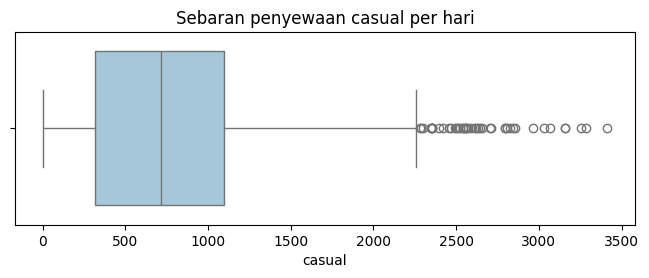

In [9]:
## Mengecek Outlier pada Penyewaan Casual
plt.figure(figsize=(8, 2.5))
sns.boxplot(x=day_df["casual"], color="#9ecae1")
plt.title("Sebaran penyewaan casual per hari")
plt.show()

Terlihat sejumlah titik di luar batas atas boxplot (*outlier*) pada penyewaan *casual*.


**Steps to Take:**
- Ubah tipe data `dteday` pada `day_df` dan `hour_df` menjadi *datetime*.
- Ganti nilai `hum = 0` dengan nilai median kelembapan.
- Ubah kode angka (`season`, `weathersit`, `workingday`, `yr`) menjadi label dan kembalikan suhu ke satuan °C agar mudah dibaca.
- 165 jam yang tidak tercatat **dibiarkan**, karena jumlahnya kecil (≈0,9%) dan sebagian besar terjadi saat dini hari ketika penyewaan nyaris nol, sehingga tidak memengaruhi analisis jam puncak. Hal ini dicatat sebagai keterbatasan data.
- *Outlier* pada `casual` **dipertahankan**, karena merupakan lonjakan wajar pada hari libur/cuaca cerah dan mencerminkan perilaku pengguna sebenarnya.


**Insight:** (Opsional)
- Kualitas data secara umum baik (tanpa *missing value* dan duplikasi), tetapi ada masalah tipe data dan kelembapan 0% yang perlu diperbaiki.

### Cleaning Data

#### Fixing tipe data dan nilai kelembapan, serta memberi label kategorik

In [11]:
# Memperbaiki tipe data dteday
day_df["dteday"] = pd.to_datetime(day_df["dteday"])
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])

print("Tipe dteday day_df :", day_df["dteday"].dtype)
print("Tipe dteday hour_df:", hour_df["dteday"].dtype)

Tipe dteday day_df : datetime64[ns]
Tipe dteday hour_df: datetime64[ns]


In [12]:
# Memperbaiki nilai kelembapan (hum) yang bernilai 0
day_df["hum"] = day_df["hum"].replace(0, day_df["hum"].median())
hour_df["hum"] = hour_df["hum"].replace(0, hour_df["hum"].median())

print("hum = 0 tersisa di day_df :", (day_df["hum"] == 0).sum())
print("hum = 0 tersisa di hour_df:", (hour_df["hum"] == 0).sum())

hum = 0 tersisa di day_df : 0
hum = 0 tersisa di hour_df: 0


In [13]:
# Mengubah kode angka menjadi label dan suhu menjadi °C
day_df["season"] = day_df["season"].map({1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"})
day_df["weathersit"] = day_df["weathersit"].map({1: "Cerah/Berawan", 2: "Berkabut/Mendung", 3: "Hujan/Salju Ringan"})
day_df["yr"] = day_df["yr"].map({0: 2011, 1: 2012})
day_df["workingday"] = day_df["workingday"].map({0: "Akhir Pekan/Libur", 1: "Hari Kerja"})
day_df["temp_c"] = day_df["temp"] * 41   # suhu asli (°C) = temp x 41

hour_df["workingday"] = hour_df["workingday"].map({0: "Akhir Pekan/Libur", 1: "Hari Kerja"})

day_df[["dteday", "season", "weathersit", "workingday", "temp_c", "cnt"]].head()

,dteday,season,weathersit,workingday,temp_c,cnt
0,2011-01-01,Spring,Berkabut/Mendung,Akhir Pekan/Libur,14.110847,985
1,2011-01-02,Spring,Berkabut/Mendung,Akhir Pekan/Libur,14.902598,801
2,2011-01-03,Spring,Cerah/Berawan,Hari Kerja,8.050924,1349
3,2011-01-04,Spring,Cerah/Berawan,Hari Kerja,8.200000,1562
4,2011-01-05,Spring,Cerah/Berawan,Hari Kerja,9.305237,1600


**Insight:** (Opsional)
- `dteday` kini bertipe *datetime* dan tidak ada lagi kelembapan 0%.
- Kolom kategorik sudah berlabel dan suhu sudah dalam °C, sehingga hasil analisis mudah dibaca.
- Tabel per jam digabung dengan informasi musim, cuaca, dan suhu harian dari `day_df` dan disimpan sebagai `dashboard/main_data.csv` untuk dashboard.

## Exploratory Data Analysis (EDA)

### Explore pola penyewaan per jam, musim, dan cuaca

In [14]:
# Explore tabel day_df
print("Rata-rata penyewaan harian per tahun:")
print(day_df.groupby(by="yr")["cnt"].mean().round(0))
print()
print("Total penyewaan casual dan registered:")
print(day_df[["casual", "registered"]].sum())

day_df[["cnt", "casual", "registered", "temp_c", "hum", "windspeed"]].describe()

Rata-rata penyewaan harian per tahun:
yr
2011    3406.0
2012    5600.0
Name: cnt, dtype: float64

Total penyewaan casual dan registered:
casual         620017
registered    2672662
dtype: int64


,cnt,casual,registered,temp_c,hum,windspeed
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,4504.348837,848.176471,3656.172367,20.310776,0.628751,0.190486
std,1937.211452,686.622488,1560.256377,7.505091,0.140518,0.077498
min,22.000000,2.000000,20.000000,2.424346,0.187917,0.022392
25%,3152.000000,315.500000,2497.000000,13.820424,0.521041,0.134950
50%,4548.000000,713.000000,3662.000000,20.431653,0.626667,0.180975
75%,5956.000000,1096.000000,4776.500000,26.872076,0.730209,0.233214
max,8714.000000,3410.000000,6946.000000,35.328347,0.972500,0.507463


In [15]:
# Explore pola penyewaan per jam (Pertanyaan 1)
pola_jam = hour_df.groupby(by=["hr", "workingday"])["cnt"].mean().unstack()

print("Jam dengan rata-rata penyewaan > 300 pada HARI KERJA:")
print(pola_jam[pola_jam["Hari Kerja"] > 300]["Hari Kerja"].round(0))
print()
print("Jam dengan rata-rata penyewaan > 300 pada AKHIR PEKAN/LIBUR:")
print(pola_jam[pola_jam["Akhir Pekan/Libur"] > 300]["Akhir Pekan/Libur"].round(0))

pola_jam.round(1)

Jam dengan rata-rata penyewaan > 300 pada HARI KERJA:
hr
8     477.0
17    525.0
18    492.0
19    348.0
Name: Hari Kerja, dtype: float64

Jam dengan rata-rata penyewaan > 300 pada AKHIR PEKAN/LIBUR:
hr
11    315.0
12    366.0
13    373.0
14    365.0
15    359.0
16    353.0
17    324.0
Name: Akhir Pekan/Libur, dtype: float64


workingday,Akhir Pekan/Libur,Hari Kerja
hr,,
0,90.8,36.8
1,69.5,16.6
2,53.2,8.7
3,25.8,4.9
4,8.3,5.4
5,8.7,24.9
6,18.7,102.5
7,43.4,290.6
8,105.7,477.0


In [16]:
# Explore musim dan cuaca (Pertanyaan 2)
musim_df = day_df.groupby(by="season")["cnt"].mean().sort_values(ascending=False)
cuaca_df = day_df.groupby(by="weathersit")["cnt"].mean().sort_values(ascending=False)

print("Rata-rata penyewaan harian per musim:")
print(musim_df.round(0))
print()
print("Rata-rata penyewaan harian per cuaca:")
print(cuaca_df.round(0))

# persentase penurunan dibandingkan kondisi terbaik
print()
print("Penurunan per musim dibanding musim terbaik (%):")
print(((1 - musim_df / musim_df.max()) * 100).round(1))
print()
print("Penurunan per cuaca dibanding cuaca terbaik (%):")
print(((1 - cuaca_df / cuaca_df.max()) * 100).round(1))

print()
print("Jumlah hari per cuaca:")
print(day_df["weathersit"].value_counts())

Rata-rata penyewaan harian per musim:
season
Fall      5644.0
Summer    4992.0
Winter    4728.0
Spring    2604.0
Name: cnt, dtype: float64

Rata-rata penyewaan harian per cuaca:
weathersit
Cerah/Berawan         4877.0
Berkabut/Mendung      4036.0
Hujan/Salju Ringan    1803.0
Name: cnt, dtype: float64

Penurunan per musim dibanding musim terbaik (%):
season
Fall       0.0
Summer    11.6
Winter    16.2
Spring    53.9
Name: cnt, dtype: float64

Penurunan per cuaca dibanding cuaca terbaik (%):
weathersit
Cerah/Berawan          0.0
Berkabut/Mendung      17.2
Hujan/Salju Ringan    63.0
Name: cnt, dtype: float64

Jumlah hari per cuaca:
weathersit
Cerah/Berawan         463
Berkabut/Mendung      247
Hujan/Salju Ringan     21
Name: count, dtype: int64


**Insight:**
- Rata-rata penyewaan harian naik dari ≈3.406 (2011) menjadi ≈5.600 (2012), pertumbuhan ≈64%.
- Pengguna terdaftar (*registered*) mendominasi, sekitar 81% dari seluruh penyewaan.

**Insight Pertanyaan 1 (pola per jam):**
- Pada **hari kerja**, rata-rata penyewaan melebihi 300 sewa per jam pada **08:00 (≈477)** dan **17:00-19:00 (≈525, ≈492, ≈348)**, yaitu jam berangkat dan pulang kerja.
- Pada **akhir pekan/libur**, penyewaan melebihi 300 pada **11:00-17:00**, dengan puncak ≈373 pada 13:00.
- Pola hari kerja berbentuk dua puncak (komuter), sedangkan akhir pekan berbentuk satu puncak landai di siang hari (rekreasi).

**Insight Pertanyaan 2 (musim & cuaca):**
- Penyewaan tertinggi pada **Fall (≈5.644/hari)** dan terendah pada **Spring (≈2.604/hari)**. Hanya Spring yang turun lebih dari 50% (**≈54%**) dari musim terbaik; Summer turun ≈12% dan Winter ≈16%.
- Dibanding cuaca cerah/berawan (≈4.877/hari), cuaca **hujan/salju ringan turun ≈63%** (≈1.803/hari), sedangkan berkabut/mendung turun ≈17%.
- Hujan/salju ringan hanya terjadi pada 21 dari 731 hari (≈3%), sehingga dampaknya besar per kejadian tetapi kecil terhadap total tahunan.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Pada jam berapa saja rata-rata penyewaan sepeda melebihi 300 sewa per jam pada hari kerja dibandingkan akhir pekan/libur selama periode 2011-2012, agar tim operasional dapat menjadwalkan distribusi sepeda pada jam-jam tersebut?

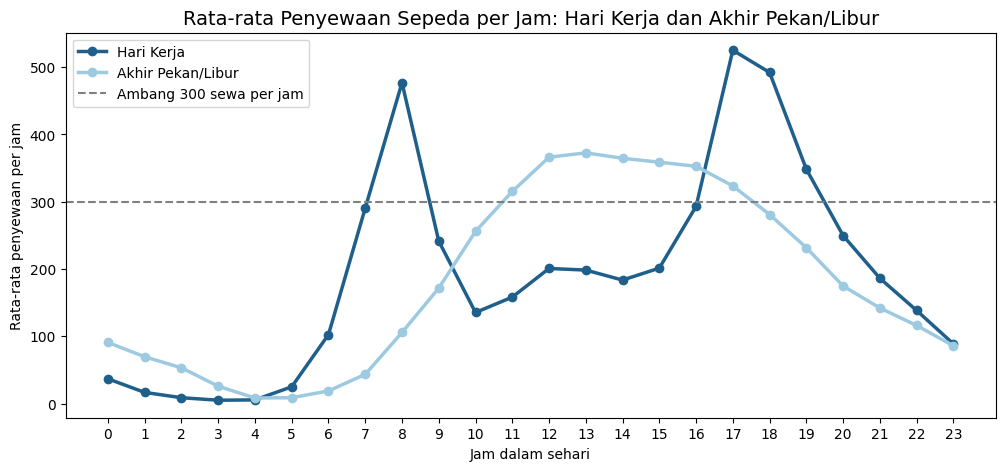

In [22]:
plt.figure(figsize=(12, 5))
plt.plot(pola_jam.index, pola_jam["Hari Kerja"], marker="o", linewidth=2.5, color="#1f5f8b", label="Hari Kerja")
plt.plot(pola_jam.index, pola_jam["Akhir Pekan/Libur"], marker="o", linewidth=2.5, color="#9ecae1", label="Akhir Pekan/Libur")
plt.axhline(300, color="grey", linestyle="--", label="Ambang 300 sewa per jam")
plt.title("Rata-rata Penyewaan Sepeda per Jam: Hari Kerja dan Akhir Pekan/Libur", fontsize=14)
plt.xlabel("Jam dalam sehari")
plt.ylabel("Rata-rata penyewaan per jam")
plt.xticks(range(0, 24))
plt.legend()
plt.show()

### Pertanyaan 2: Pada musim dan kondisi cuaca apa rata-rata penyewaan harian turun lebih dari 50% dibandingkan musim dan cuaca terbaiknya selama periode 2011-2012, agar tim pemasaran dan perawatan dapat merencanakan promosi serta jadwal perawatan pada periode tersebut?

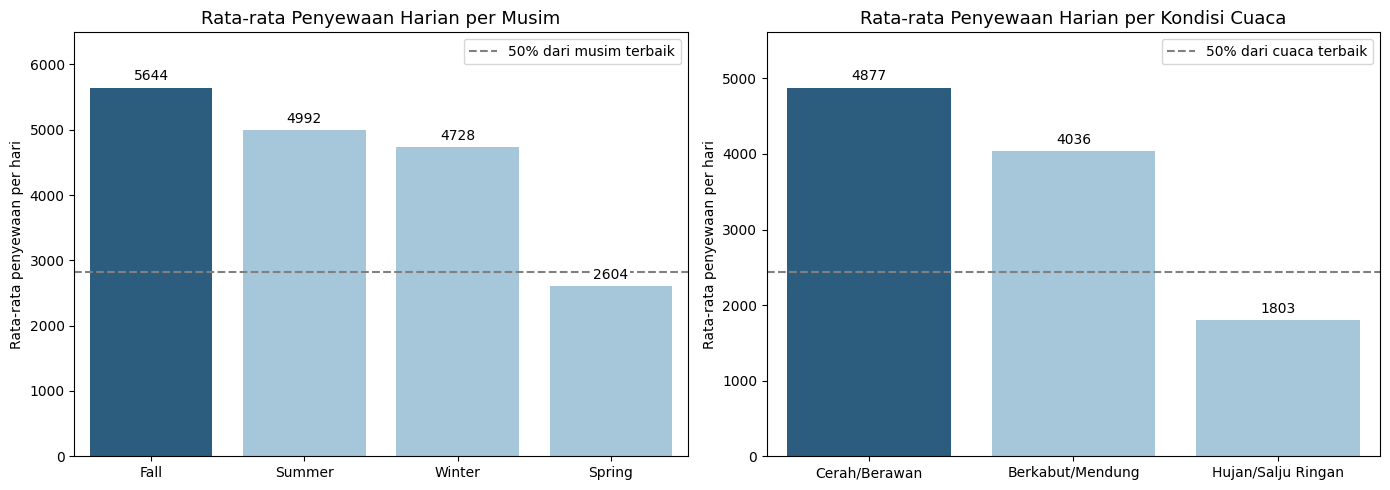

In [23]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

colors_musim = ["#1f5f8b", "#9ecae1", "#9ecae1", "#9ecae1"]   # biru tua = tertinggi
sns.barplot(x=musim_df.index, y=musim_df.values, hue=musim_df.index, palette=colors_musim, legend=False, ax=ax[0])
ax[0].axhline(musim_df.max() * 0.5, color="grey", linestyle="--", label="50% dari musim terbaik")
for container in ax[0].containers:
    ax[0].bar_label(container, fmt="%.0f", padding=3, bbox=dict(facecolor="white", edgecolor="none", pad=1))
ax[0].set_ylim(0, musim_df.max() * 1.15)
ax[0].set_title("Rata-rata Penyewaan Harian per Musim", fontsize=13)
ax[0].set_xlabel(None)
ax[0].set_ylabel("Rata-rata penyewaan per hari")
ax[0].legend()

colors_cuaca = ["#1f5f8b", "#9ecae1", "#9ecae1"]   # biru tua = tertinggi
sns.barplot(x=cuaca_df.index, y=cuaca_df.values, hue=cuaca_df.index, palette=colors_cuaca, legend=False, ax=ax[1])
ax[1].axhline(cuaca_df.max() * 0.5, color="grey", linestyle="--", label="50% dari cuaca terbaik")
for container in ax[1].containers:
    ax[1].bar_label(container, fmt="%.0f", padding=3, bbox=dict(facecolor="white", edgecolor="none", pad=1))
ax[1].set_ylim(0, cuaca_df.max() * 1.15)
ax[1].set_title("Rata-rata Penyewaan Harian per Kondisi Cuaca", fontsize=13)
ax[1].set_xlabel(None)
ax[1].set_ylabel("Rata-rata penyewaan per hari")
ax[1].legend()

plt.tight_layout()
plt.show()

**Insight Pertanyaan 1**:
- Garis hari kerja (biru) memiliki **dua puncak tajam** pada 08:00 (≈477 sewa/jam) dan 17:00 (≈525 sewa/jam). Pola ini khas pengguna komuter yang berangkat dan pulang kerja.
- Garis akhir pekan/libur (oranye) berbentuk **satu puncak landai** pada 11:00-16:00 dengan puncak ≈373 sewa/jam pada 13:00, khas penggunaan rekreasi.
- Pada hari kerja, penyewaan melewati ambang 300 hanya pada **08:00 dan 17:00-19:00**; pada akhir pekan/libur pada **11:00-17:00**.
- Pada siang hari kerja (10:00-15:00), penyewaan turun ke ≈135-200 sewa/jam, jauh di bawah akhir pekan (≈256-373 sewa/jam). Pada jam ini sepeda lebih banyak menganggur di hari kerja.
- Dini hari (00:00-05:00) penyewaan sangat rendah di kedua jenis hari.

**Insight Pertanyaan 2:**
- Penyewaan tertinggi terjadi pada **Fall (≈5.644/hari)** dan terendah pada **Spring (≈2.604/hari)**. Hanya Spring yang jatuh di bawah garis 50% (turun ≈54%), sedangkan Summer (≈12%) dan Winter (≈16%) turunnya jauh lebih kecil.
- Pada grafik cuaca, **hujan/salju ringan (≈1.803/hari)** turun ≈63% dari cuaca cerah/berawan (≈4.877/hari) dan berada di bawah garis 50%. Cuaca berkabut/mendung (≈4.036/hari) hanya turun ≈17%.
- Hujan/salju ringan hanya terjadi pada 21 dari 731 hari (≈3%). Dampaknya besar per kejadian, tetapi kecil terhadap total penyewaan tahunan.
- Artinya, permintaan paling rawan turun pada **musim Spring** dan **hari hujan**, yang cocok untuk promo dan jadwal *maintenance*.

## Analisis Lanjutan (Opsional)

Teknik **clustering tanpa algoritma *machine learning*** diterapkan dengan *manual grouping* dan *binning* menggunakan `pd.cut()`. Tujuannya mengelompokkan data ke dalam kategori yang bermakna bagi bisnis, sehingga pola permintaan lebih mudah dibaca. RFM dan *geospatial analysis* tidak dipakai karena dataset tidak memiliki ID pelanggan maupun data lokasi.

segmen_waktu
Dini hari (00-05)     3.2
Pagi (06-09)         19.1
Siang (10-15)        30.5
Sore (16-19)         33.4
Malam (20-23)        13.7
Name: cnt, dtype: float64


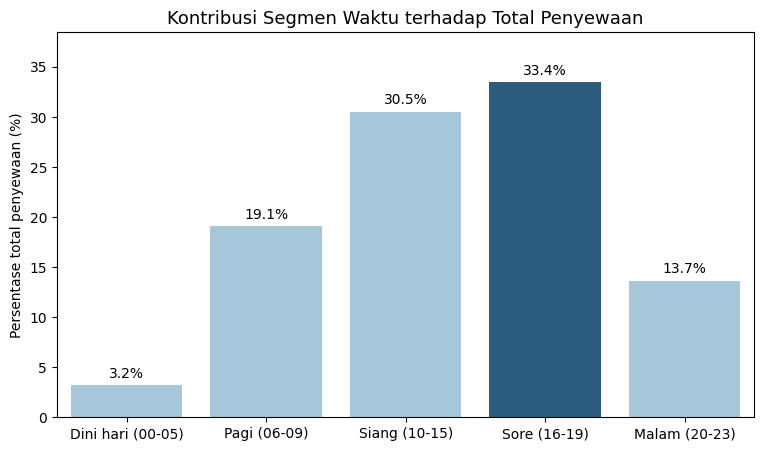

In [24]:
# Segmen waktu: kapan penyewaan paling banyak terjadi?
hour_df["segmen_waktu"] = pd.cut(
    hour_df["hr"],
    bins=[-1, 5, 9, 15, 19, 23],
    labels=["Dini hari (00-05)", "Pagi (06-09)", "Siang (10-15)", "Sore (16-19)", "Malam (20-23)"]
)

segmen_df = hour_df.groupby(by="segmen_waktu", observed=True)["cnt"].sum()
segmen_df = segmen_df / segmen_df.sum() * 100
print(segmen_df.round(1))

plt.figure(figsize=(9, 5))
colors_segmen = ["#1f5f8b" if nilai == segmen_df.max() else "#9ecae1" for nilai in segmen_df.values]
ax_segmen = sns.barplot(x=segmen_df.index.astype(str), y=segmen_df.values, hue=segmen_df.index.astype(str), palette=colors_segmen, legend=False)
for container in ax_segmen.containers:
    ax_segmen.bar_label(container, fmt="%.1f%%", padding=3, bbox=dict(facecolor="white", edgecolor="none", pad=1))
ax_segmen.set_ylim(0, segmen_df.max() * 1.15)
plt.title("Kontribusi Segmen Waktu terhadap Total Penyewaan", fontsize=13)
plt.xlabel(None)
plt.ylabel("Persentase total penyewaan (%)")
plt.show()

kategori_suhu
Dingin (≤10°C)      1678.0
Sejuk (10-20°C)     3692.0
Hangat (20-30°C)    5662.0
Panas (>30°C)       5410.0
Name: cnt, dtype: float64


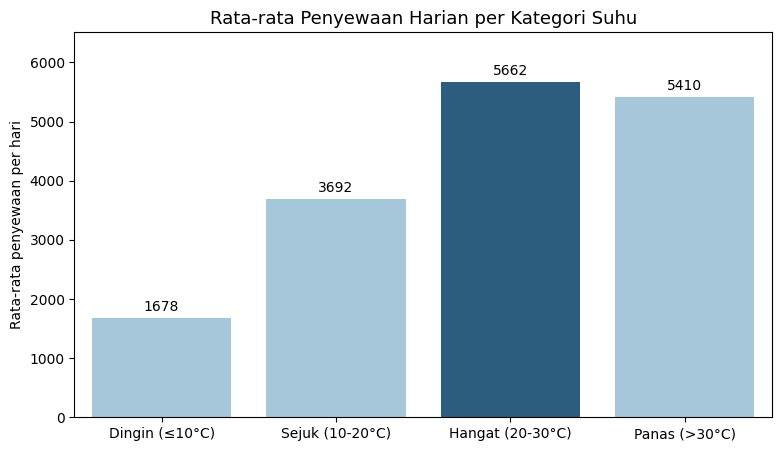

In [25]:
# Kategori suhu: pada suhu berapa penyewaan paling tinggi?
day_df["kategori_suhu"] = pd.cut(
    day_df["temp_c"],
    bins=[0, 10, 20, 30, 50],
    labels=["Dingin (≤10°C)", "Sejuk (10-20°C)", "Hangat (20-30°C)", "Panas (>30°C)"]
)

suhu_df = day_df.groupby(by="kategori_suhu", observed=True)["cnt"].mean()
print(suhu_df.round(0))

plt.figure(figsize=(9, 5))
colors_suhu = ["#1f5f8b" if nilai == suhu_df.max() else "#9ecae1" for nilai in suhu_df.values]
ax_suhu = sns.barplot(x=suhu_df.index.astype(str), y=suhu_df.values, hue=suhu_df.index.astype(str), palette=colors_suhu, legend=False)
for container in ax_suhu.containers:
    ax_suhu.bar_label(container, fmt="%.0f", padding=3, bbox=dict(facecolor="white", edgecolor="none", pad=1))
ax_suhu.set_ylim(0, suhu_df.max() * 1.15)
plt.title("Rata-rata Penyewaan Harian per Kategori Suhu", fontsize=13)
plt.xlabel(None)
plt.ylabel("Rata-rata penyewaan per hari")
plt.show()

tingkat_permintaan  Rendah (<3.000)  Sedang (3.000-6.000)  Tinggi (>6.000)
season                                                                    
Spring                         65.0                  33.0              3.0
Summer                         14.0                  53.0             34.0
Fall                            2.0                  56.0             41.0
Winter                         15.0                  66.0             20.0


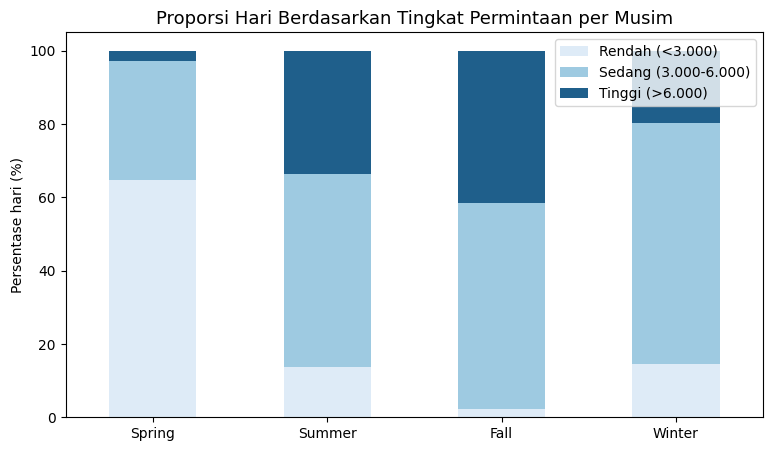

In [26]:
# Tingkat permintaan harian: musim mana yang paling sering permintaannya rendah?
day_df["tingkat_permintaan"] = pd.cut(
    day_df["cnt"],
    bins=[0, 3000, 6000, 10000],
    labels=["Rendah (<3.000)", "Sedang (3.000-6.000)", "Tinggi (>6.000)"]
)

tingkat_df = pd.crosstab(day_df["season"], day_df["tingkat_permintaan"], normalize="index") * 100
tingkat_df = tingkat_df.loc[["Spring", "Summer", "Fall", "Winter"]]
print(tingkat_df.round(0))

tingkat_df.plot(kind="bar", stacked=True, figsize=(9, 5), color=["#deebf7", "#9ecae1", "#1f5f8b"])
plt.title("Proporsi Hari Berdasarkan Tingkat Permintaan per Musim", fontsize=13)
plt.xlabel(None)
plt.ylabel("Persentase hari (%)")
plt.xticks(rotation=0)
plt.legend(title=None)
plt.show()

**Insight:** (Opsional)
- **Sore (16-19) dan siang (10-15)** menyumbang ≈64% total penyewaan, sedangkan dini hari hanya ≈3%.
- Penyewaan tertinggi pada suhu **20-30°C** (≈5.662/hari) dan tidak naik lagi saat suhu >30°C (≈5.410). Pada suhu dingin (≤10°C) penyewaan hanya ≈1.678/hari.
- Pada **Spring ≈65% harinya** berpermintaan rendah (<3.000), sedangkan Summer dan Fall memiliki ≈34% dan ≈41% hari berpermintaan tinggi (>6.000).

### Menyimpan data untuk dashboard
Tabel per jam digabung dengan informasi musim, cuaca, dan suhu harian dari `day_df`, lalu disimpan sebagai `dashboard/main_data.csv` agar dashboard Streamlit memakai data bersih yang sama dengan notebook.

In [27]:
import os

main_data = pd.merge(
    left=hour_df[["dteday", "hr", "workingday", "casual", "registered", "cnt"]],
    right=day_df[["dteday", "season", "weathersit", "temp_c"]],
    how="left",
    on="dteday"
)

os.makedirs("dashboard", exist_ok=True)
main_data.to_csv("dashboard/main_data.csv", index=False)
main_data.head()

,dteday,hr,workingday,casual,registered,cnt,season,weathersit,temp_c
0,2011-01-01,0,Akhir Pekan/Libur,3,13,16,Spring,Berkabut/Mendung,14.110847
1,2011-01-01,1,Akhir Pekan/Libur,8,32,40,Spring,Berkabut/Mendung,14.110847
2,2011-01-01,2,Akhir Pekan/Libur,5,27,32,Spring,Berkabut/Mendung,14.110847
3,2011-01-01,3,Akhir Pekan/Libur,3,10,13,Spring,Berkabut/Mendung,14.110847
4,2011-01-01,4,Akhir Pekan/Libur,0,1,1,Spring,Berkabut/Mendung,14.110847


## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Rata-rata penyewaan melebihi 300 sewa per jam pada **08:00 dan 17:00-19:00 di hari kerja** (puncak ≈525 pada 17:00), serta pada **11:00-17:00 di akhir pekan/libur** (puncak ≈373 pada 13:00). Hari kerja berpola dua puncak komuter, akhir pekan berpola satu puncak siang.
- **Conclusion pertanyaan 2:** Hanya **Spring** (turun ≈54% dari Fall, ≈2.604 dibandingkan dengan ≈5.644 per hari) dan **cuaca hujan/salju ringan** (turun ≈63% dari cuaca cerah, ≈1.803 dibandingkan dengan ≈4.877 per hari) yang turun lebih dari 50% dari kondisi terbaiknya. Penyewaan paling tinggi pada suhu 20-30°C.

**Rekomendasi Action Item:**
- **Distribusi armada:** pada hari kerja, pastikan stok sepeda penuh di stasiun sebelum **07:00** dan **16:30**, lalu lakukan penyeimbangan ulang sebaran sepeda pada **09:00-10:00** dan **19:00-20:00**. Pada akhir pekan/libur, siapkan stok lebih banyak di area rekreasi sebelum **10:00**.
- **Perawatan:** jadwalkan perawatan massal pada **dini hari (00:00-05:00)** yang hanya ≈3% penyewaan, dan lakukan perawatan besar pada **musim Spring** atau saat prakiraan hujan.
- **Promosi:** berikan promosi/diskon pada **Spring** dan saat cuaca berkabut atau hujan ringan untuk menjaga permintaan, serta tawarkan paket keanggotaan kepada pengguna *casual* akhir pekan.
- **Kapasitas:** tambah armada dan teknisi pada **Summer-Fall** saat cuaca cerah, dan kurangi sepeda yang beroperasi saat prakiraan hujan.